# Tutorial: Horizontal Stratigraphic Model - Interface and Scalar Field Visualization

This tutorial demonstrates a simple horizontal stratigraphic model with two layers (layer1 and layer2).
We'll visualize:
1. The extracted interface (lithology)
2. The scalar field that defines the interface

**Note:** This notebook is configured to use PyTorch as the backend.

In [31]:
# Import necessary libraries
import matplotlib
# matplotlib.use('Agg')  # Use non-interactive backend (uncomment if needed)
import gempy as gp
import gempy_viewer as gpv
import numpy as np
import json
from pathlib import Path
import matplotlib.pyplot as plt
from datetime import datetime
from gempy.core.data.gempy_engine_config import GemPyEngineConfig
from gempy_engine.config import AvailableBackends

In [32]:
# Load the model from JSON
from gempy.modules.json_io.json_operations import JsonIO

# Use the existing JSON file
json_path = "/Users/flow/git/gempy/examples/tutorials/z_other_tutorials/json_io/horizontal_stratigraphic.json"
model = JsonIO.load_model_from_json(json_path)

print("Model loaded successfully")
print(f"Model name: {model.meta.name}")
print(f"Number of series: {len(model.structural_frame.structural_groups)}")
print(f"Number of surfaces: {len(model.structural_frame.structural_elements) - 1}")  # -1 for basement

Model loaded successfully
Model name: horizontal_stratigraphic
Number of series: 1
Number of surfaces: 2


In [33]:
# Compute the geological model with PyTorch backend
engine_config = GemPyEngineConfig(
    backend=AvailableBackends.PYTORCH,
    use_gpu=False,
    dtype='float64'
)

gp.compute_model(model, engine_config=engine_config)
print("✓ Model computed successfully")

Setting Backend To: AvailableBackends.PYTORCH
Using sequential processing for 2 surfaces
✓ Model computed successfully


## Plot 1: Extracted Interface (Lithology)

This shows the computed lithology - the interface between layer1 and layer2.

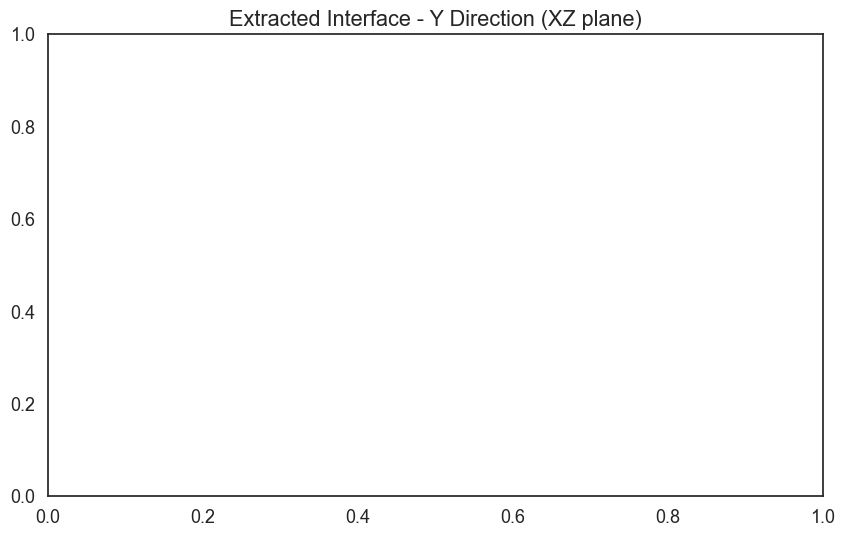

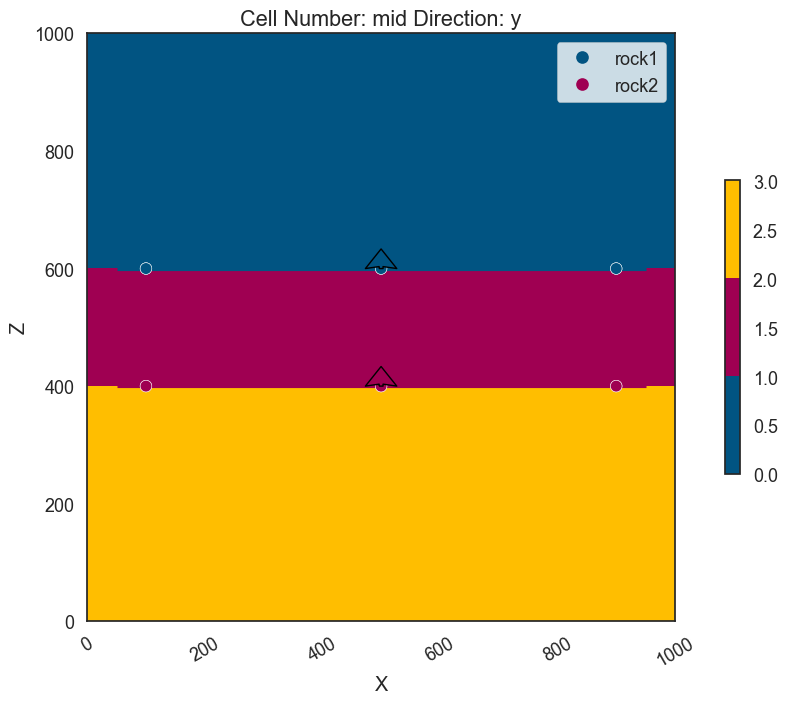

In [34]:
# Plot the extracted interface (lithology) in y direction
fig, ax = plt.subplots(figsize=(10, 6))
gpv.plot_2d(
    model, 
    direction='y', 
    show_data=True,
    show_results=True,
    show_boundaries=True,
    ax=ax
)
ax.set_title("Extracted Interface - Y Direction (XZ plane)")
plt.tight_layout()
plt.show()

## Plot 2: Scalar Field

This shows the scalar field that defines the interface. The interface is an isosurface in this scalar field.

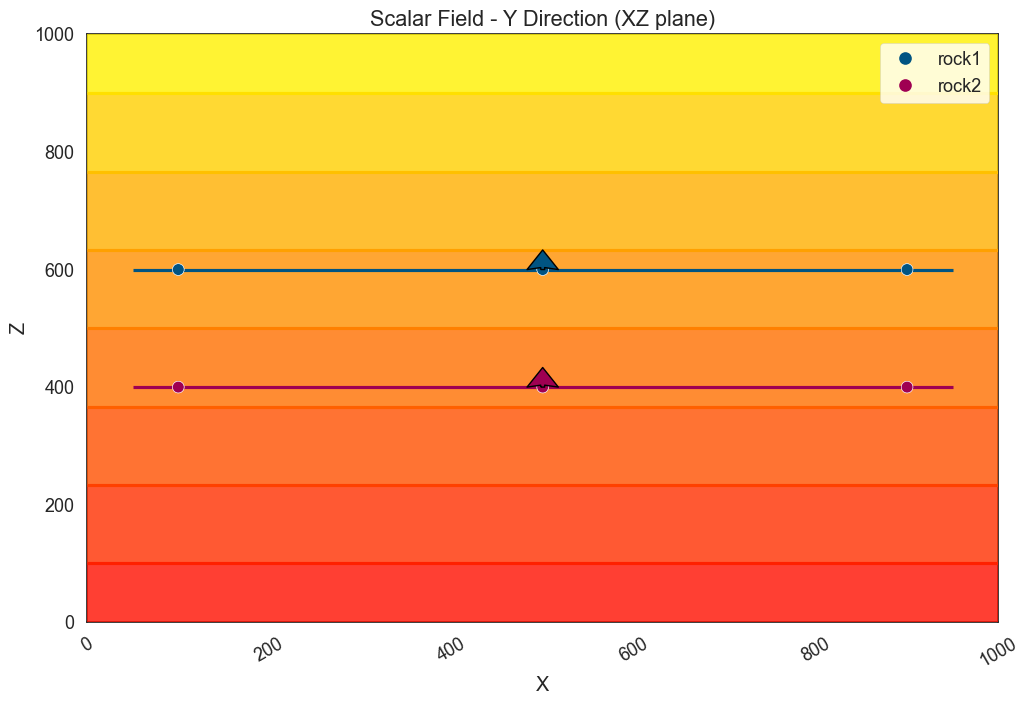

✓ Scalar field plotted
Note: The interface occurs where the scalar field equals the interface value


In [35]:
# Plot the scalar field in y direction
# series_n=0 corresponds to the first (and only) series
p2d = gpv.plot_2d(
    model=model,
    series_n=0,  # First (and only) series
    direction='y',
    show_data=True,
    show_scalar=True,
    show_lith=False,  # Don't show lithology, just scalar field
    show_boundaries=True
)
p2d.axes[0].set_title("Scalar Field - Y Direction (XZ plane)")
plt.tight_layout()
plt.show()

print("✓ Scalar field plotted")
print(f"Note: The interface occurs where the scalar field equals the interface value")

In [36]:
# Display interface values for reference
print("\n=== Interface Values ===")
for element in model.structural_frame.structural_elements[:-1]:  # Exclude basement
    print(f"{element.name}: scalar_field_at_interface = {element.scalar_field_at_interface:.6f}")


=== Interface Values ===
rock1: scalar_field_at_interface = 0.125000
rock2: scalar_field_at_interface = -0.125000


## Plot 3: 1D Scalar Field Profile

Extract and plot the scalar field values along the z-axis at a specific x,y location.

In [37]:
# Extract 1D scalar field profile along z-axis at a specific x,y location
print("=== Extracting 1D Scalar Field Profile ===\n")

# Choose location (middle of the model)
x_loc = 0.5
y_loc = 0.5

print(f"Location: x={x_loc}, y={y_loc}")

# Get scalar field matrix from raw arrays
scalar_field_matrix = model.solutions.raw_arrays.scalar_field_matrix
print(f"Scalar field matrix shape: {scalar_field_matrix.shape}")
print(f"  - Series: {scalar_field_matrix.shape[0]}")
print(f"  - Grid points: {scalar_field_matrix.shape[1]}")

# Get the scalar field for the first (and only) series
scalar_field_flat = scalar_field_matrix[0]  # series1 (index 0)
print(f"Scalar field values shape: {scalar_field_flat.shape}")

# Get grid information
regular_grid = model.grid.regular_grid
grid_resolution = regular_grid.resolution
grid_extent = regular_grid.extent

print(f"\nGrid resolution: {grid_resolution}")
print(f"Grid extent: {grid_extent}")

# Calculate grid cell size
nx, ny, nz = grid_resolution
dx = (grid_extent[1] - grid_extent[0]) / nx
dy = (grid_extent[3] - grid_extent[2]) / ny
dz = (grid_extent[5] - grid_extent[4]) / nz

print(f"Grid cell size: dx={dx:.3f}, dy={dy:.3f}, dz={dz:.3f}")

# Find grid indices for x_loc, y_loc
x_idx = int((x_loc - grid_extent[0]) / dx)
y_idx = int((y_loc - grid_extent[2]) / dy)

# Clamp to valid range
x_idx = max(0, min(nx - 1, x_idx))
y_idx = max(0, min(ny - 1, y_idx))

print(f"\nGrid indices: x_idx={x_idx}, y_idx={y_idx}")
print(f"  Actual x position: {grid_extent[0] + x_idx * dx:.3f}")
print(f"  Actual y position: {grid_extent[2] + y_idx * dy:.3f}")

# Reshape scalar field to 3D grid
# Grid is organized as: x varies fastest, then y, then z
# So: index = x + y*nx + z*nx*ny
scalar_field_3d = scalar_field_flat.reshape(nx, ny, nz)

# Extract values along z-axis at x_idx, y_idx
z_coords = []
scalar_values = []

for z_idx in range(nz):
    z_coord = grid_extent[4] + z_idx * dz
    sf_value = scalar_field_3d[x_idx, y_idx, z_idx]
    z_coords.append(z_coord)
    scalar_values.append(sf_value)

z_coords = np.array(z_coords)
scalar_values = np.array(scalar_values)

print(f"\nExtracted profile:")
print(f"  Z-coordinates shape: {z_coords.shape}")
print(f"  Scalar field values shape: {scalar_values.shape}")
print(f"  Scalar field range: [{scalar_values.min():.4f}, {scalar_values.max():.4f}]")
print(f"  Z-range: [{z_coords.min():.3f}, {z_coords.max():.3f}]")

=== Extracting 1D Scalar Field Profile ===

Location: x=0.5, y=0.5
Scalar field matrix shape: (1, 1000)
  - Series: 1
  - Grid points: 1000
Scalar field values shape: (1000,)

Grid resolution: [10 10 10]
Grid extent: [   0. 1000.    0. 1000.    0. 1000.]
Grid cell size: dx=100.000, dy=100.000, dz=100.000

Grid indices: x_idx=0, y_idx=0
  Actual x position: 0.000
  Actual y position: 0.000

Extracted profile:
  Z-coordinates shape: (10,)
  Scalar field values shape: (10,)
  Scalar field range: [-0.5625, 0.5625]
  Z-range: [0.000, 900.000]


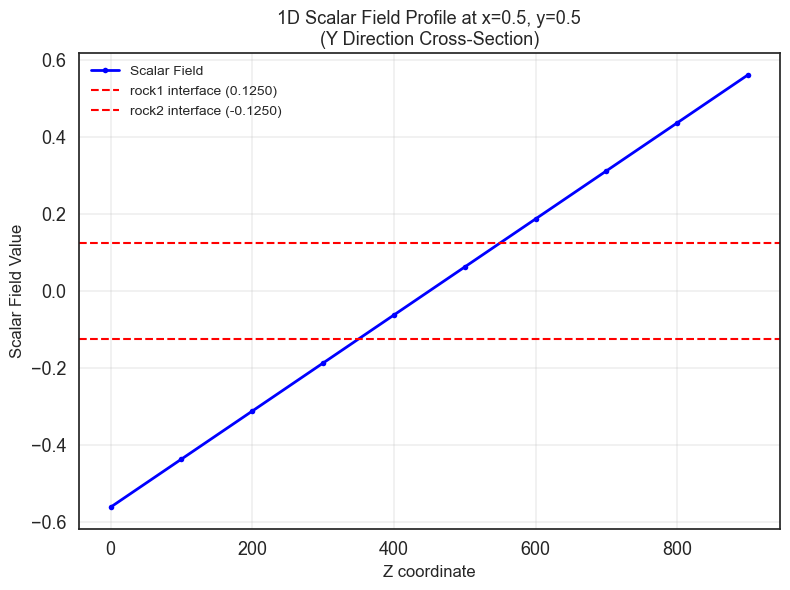

✓ 1D scalar field profile plotted


In [38]:
# Plot 1D scalar field profile
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(z_coords, scalar_values, 'b-', linewidth=2, marker='o', markersize=4, label='Scalar Field')

# Add interface lines
for element in model.structural_frame.structural_elements[:-1]:  # Exclude basement
    interface_value = element.scalar_field_at_interface
    ax.axhline(
        y=interface_value, 
        color='r', 
        linestyle='--', 
        linewidth=1.5, 
        label=f'{element.name} interface ({interface_value:.4f})'
    )

ax.set_xlabel('Z coordinate', fontsize=12)
ax.set_ylabel('Scalar Field Value', fontsize=12)
ax.set_title(f'1D Scalar Field Profile at x={x_loc}, y={y_loc}\n(Y Direction Cross-Section)', fontsize=13)
ax.legend(loc='best', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✓ 1D scalar field profile plotted")

## Plot 4: Custom Grid Scalar Field Comparison

Now let's compute the scalar field at the same location using a custom grid and compare with the regular grid results.

In [39]:
# Create custom grid at the same location (x=0.5, y=0.5) with same z-resolution
print("=== Creating Custom Grid ===\n")

# Use the same z-coordinates as the regular grid
custom_z_coords = z_coords.copy()  # Same z-coordinates as regular grid
n_custom_points = len(custom_z_coords)

# Create custom grid coordinates
custom_coords = np.column_stack([
    np.full(n_custom_points, x_loc),
    np.full(n_custom_points, y_loc),
    custom_z_coords
])

print(f"Custom grid coordinates shape: {custom_coords.shape}")
print(f"  Location: x={x_loc}, y={y_loc}")
print(f"  Z-range: [{custom_z_coords.min():.3f}, {custom_z_coords.max():.3f}]")
print(f"  Number of points: {n_custom_points}")

# Set octree levels to 1 (minimal for custom grid)
original_octree_levels = model.interpolation_options.number_octree_levels
model.interpolation_options.number_octree_levels = 1
print(f"\nSet octree levels to 1 (was {original_octree_levels})")

# Compute on custom grid
print("\nComputing on custom grid...")
lithology_custom = gp.compute_model_at(model, custom_coords, engine_config=engine_config)
print(f"Custom grid lithology shape: {lithology_custom.shape}")

# Extract scalar field from custom grid solution
sol_custom = model.solutions
print(f"\n=== Extracting Scalar Field from Custom Grid ===")

# Check root_output structure
if hasattr(sol_custom, 'root_output'):
    root = sol_custom.root_output
    if hasattr(root, 'outputs_centers'):
        print(f"Number of output centers: {len(root.outputs_centers)}")
        
        # Get scalar field from first (and only) series
        if len(root.outputs_centers) > 0:
            series_output = root.outputs_centers[0]  # series1 (index 0)
            
            if hasattr(series_output, 'scalar_fields'):
                sf = series_output.scalar_fields
                if hasattr(sf, 'exported_fields'):
                    ef = sf.exported_fields
                    if hasattr(ef, 'scalar_field'):
                        custom_sf_tensor = ef.scalar_field
                        
                        print(f"Custom grid scalar field tensor shape: {custom_sf_tensor.shape}")
                        
                        # Convert to numpy
                        if hasattr(custom_sf_tensor, 'detach'):
                            custom_sf_values = custom_sf_tensor.detach().cpu().numpy()
                        elif hasattr(custom_sf_tensor, 'numpy'):
                            custom_sf_values = custom_sf_tensor.numpy()
                        else:
                            custom_sf_values = np.asarray(custom_sf_tensor)
                        
                        custom_sf_values = custom_sf_values.flatten()
                        print(f"Custom scalar field values shape: {custom_sf_values.shape}")
                        print(f"Custom scalar field range: [{custom_sf_values.min():.4f}, {custom_sf_values.max():.4f}]")
                        
                        # Handle shape mismatch
                        if len(custom_sf_values) != n_custom_points:
                            print(f"\n⚠️ Shape mismatch: {len(custom_sf_values)} values for {n_custom_points} points")
                            
                            # Check if values are stacked by series
                            n_series = len(root.outputs_centers)
                            if len(custom_sf_values) == n_custom_points * n_series:
                                # Values are interleaved: [series0_pt0, series1_pt0, ...]
                                custom_sf_values = custom_sf_values[0::n_series]  # Extract first series
                                print(f"  ✓ Extracted series 0 from interleaved values")
                            elif len(custom_sf_values) > n_custom_points:
                                # More values - might be octree structure
                                print(f"  Using first {n_custom_points} values")
                                custom_sf_values = custom_sf_values[:n_custom_points]
                            else:
                                print(f"  ⚠️ Fewer values than expected - using all available")
                                custom_z_coords = custom_z_coords[:len(custom_sf_values)]
                        
                        print(f"\nFinal custom grid scalar field:")
                        print(f"  Values shape: {custom_sf_values.shape}")
                        print(f"  Z-coords shape: {custom_z_coords.shape}")
                    else:
                        raise ValueError("scalar_field not found in exported_fields")
                else:
                    raise ValueError("exported_fields not found")
            else:
                raise ValueError("scalar_fields not found")
        else:
            raise ValueError("No output centers found")
    else:
        raise ValueError("outputs_centers not found")
else:
    raise ValueError("root_output not found")

# Restore octree levels
model.interpolation_options.number_octree_levels = original_octree_levels
print(f"\nRestored octree levels to {original_octree_levels}")

=== Creating Custom Grid ===

Custom grid coordinates shape: (10, 3)
  Location: x=0.5, y=0.5
  Z-range: [0.000, 900.000]
  Number of points: 10

Set octree levels to 1 (was 4)

Computing on custom grid...
Active grids: GridTypes.CUSTOM|NONE
Setting Backend To: AvailableBackends.PYTORCH
Using sequential processing for 2 surfaces
Custom grid lithology shape: (10,)

=== Extracting Scalar Field from Custom Grid ===
Number of output centers: 1
Custom grid scalar field tensor shape: torch.Size([82])
Custom scalar field values shape: (82,)
Custom scalar field range: [-0.6250, 0.6250]

⚠️ Shape mismatch: 82 values for 10 points
  Using first 10 values

Final custom grid scalar field:
  Values shape: (10,)
  Z-coords shape: (10,)

Restored octree levels to 4


=== Comparison: Regular Grid vs Custom Grid ===

Comparing 10 points
Regular grid SF range: [-0.5625, 0.5625]
Custom grid SF range: [-0.6250, 0.3125]

Differences:
  Mean absolute difference: 0.462500
  Max absolute difference: 1.062502


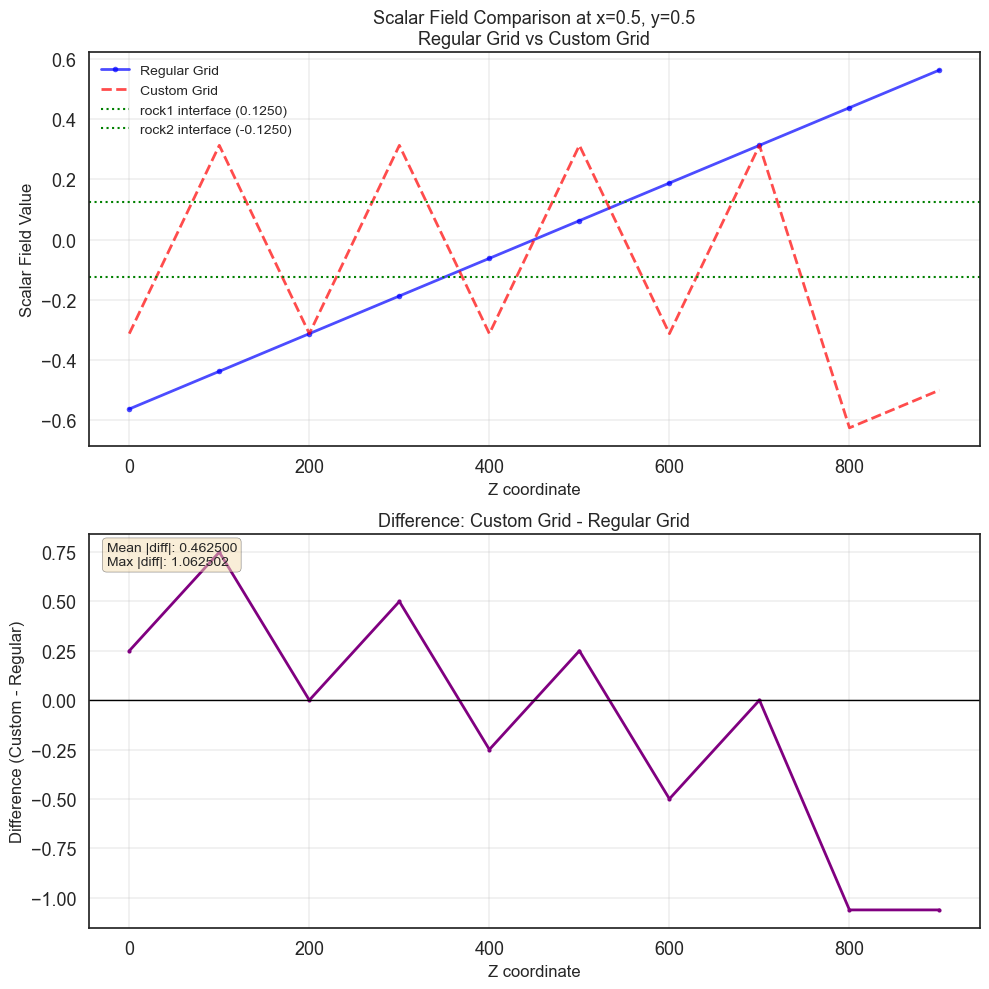


✓ Comparison plot created
⚠️ Significant differences detected - investigation needed


In [40]:
# Compare Regular Grid vs Custom Grid Scalar Field Values
print("=== Comparison: Regular Grid vs Custom Grid ===\n")

# Ensure same length for comparison
min_len = min(len(scalar_values), len(custom_sf_values))
regular_sf_compare = scalar_values[:min_len]
custom_sf_compare = custom_sf_values[:min_len]
z_coords_compare = z_coords[:min_len]

print(f"Comparing {min_len} points")
print(f"Regular grid SF range: [{regular_sf_compare.min():.4f}, {regular_sf_compare.max():.4f}]")
print(f"Custom grid SF range: [{custom_sf_compare.min():.4f}, {custom_sf_compare.max():.4f}]")

# Calculate differences
differences = custom_sf_compare - regular_sf_compare
mean_diff = np.mean(np.abs(differences))
max_diff = np.max(np.abs(differences))

print(f"\nDifferences:")
print(f"  Mean absolute difference: {mean_diff:.6f}")
print(f"  Max absolute difference: {max_diff:.6f}")

# Plot comparison
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Plot 1: Both curves overlaid
ax1 = axes[0]
ax1.plot(z_coords_compare, regular_sf_compare, 'b-', linewidth=2, marker='o', markersize=4, 
         label='Regular Grid', alpha=0.7)
ax1.plot(z_coords_compare, custom_sf_compare, 'r--', linewidth=2, marker='x', markersize=4, 
         label='Custom Grid', alpha=0.7)

# Add interface lines
for element in model.structural_frame.structural_elements[:-1]:
    interface_value = element.scalar_field_at_interface
    ax1.axhline(y=interface_value, color='g', linestyle=':', linewidth=1.5, 
                label=f'{element.name} interface ({interface_value:.4f})')

ax1.set_xlabel('Z coordinate', fontsize=12)
ax1.set_ylabel('Scalar Field Value', fontsize=12)
ax1.set_title(f'Scalar Field Comparison at x={x_loc}, y={y_loc}\nRegular Grid vs Custom Grid', fontsize=13)
ax1.legend(loc='best', fontsize=10)
ax1.grid(True, alpha=0.3)

# Plot 2: Difference
ax2 = axes[1]
ax2.plot(z_coords_compare, differences, 'purple', linewidth=2, marker='o', markersize=3)
ax2.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax2.set_xlabel('Z coordinate', fontsize=12)
ax2.set_ylabel('Difference (Custom - Regular)', fontsize=12)
ax2.set_title('Difference: Custom Grid - Regular Grid', fontsize=13)
ax2.grid(True, alpha=0.3)

# Add statistics
ax2.text(0.02, 0.98, f'Mean |diff|: {mean_diff:.6f}\nMax |diff|: {max_diff:.6f}', 
         transform=ax2.transAxes, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5), fontsize=10)

plt.tight_layout()
plt.show()

print("\n✓ Comparison plot created")
if mean_diff < 1e-5:
    print("✓ Values match very closely!")
elif mean_diff < 1e-3:
    print("⚠️ Small differences detected (likely numerical precision)")
else:
    print("⚠️ Significant differences detected - investigation needed")

## Plot 5: Lithology Comparison

Compare lithology values from regular grid vs custom grid to see if the issue is specific to scalar fields or affects all outputs.

In [43]:
# Extract lithology from regular grid at the same location
print("=== Extracting Lithology from Regular Grid ===\n")

# Check what's available in raw_arrays
print("Available in raw_arrays:")
print(f"  lith_block: {hasattr(model.solutions.raw_arrays, 'lith_block')}")
if hasattr(model.solutions.raw_arrays, 'lith_block'):
    lith_block = model.solutions.raw_arrays.lith_block
    print(f"    lith_block shape: {lith_block.shape if hasattr(lith_block, 'shape') else 'N/A'}")
    print(f"    lith_block size: {lith_block.size if hasattr(lith_block, 'size') else 'N/A'}")

print(f"  block_matrix: {hasattr(model.solutions.raw_arrays, 'block_matrix')}")
if hasattr(model.solutions.raw_arrays, 'block_matrix'):
    block_matrix = model.solutions.raw_arrays.block_matrix
    print(f"    block_matrix shape: {block_matrix.shape if hasattr(block_matrix, 'shape') else 'N/A'}")
    print(f"    block_matrix size: {block_matrix.size if hasattr(block_matrix, 'size') else 'N/A'}")

# Helper to safely get array sizes (handles torch tensors)
def safe_size(obj):
    if hasattr(obj, 'numel'):
        return int(obj.numel())
    size_attr = getattr(obj, 'size', None)
    if callable(size_attr):
        return int(size_attr())
    if size_attr is not None:
        return int(size_attr)
    if hasattr(obj, 'shape'):
        try:
            return int(np.prod(obj.shape))
        except Exception:
            return 0
    try:
        return len(obj)
    except Exception:
        return 0

# Check octree output structure (lithology might be stored there)
print(f"\nChecking octree output structure:")
print(f"  octrees_output: {hasattr(model.solutions, 'octrees_output')}")
if hasattr(model.solutions, 'octrees_output') and len(model.solutions.octrees_output) > 0:
    octree_output = model.solutions.octrees_output[-1]  # Last octree level
    print(f"    Last octree level available")
    print(f"    last_output_center: {hasattr(octree_output, 'last_output_center')}")
    if hasattr(octree_output, 'last_output_center'):
        last_output = octree_output.last_output_center
        print(f"      ids_block: {hasattr(last_output, 'ids_block')}")
        if hasattr(last_output, 'ids_block'):
            ids_block = last_output.ids_block
            print(f"        ids_block shape: {ids_block.shape if hasattr(ids_block, 'shape') else 'N/A'}")
            print(f"        ids_block size: {safe_size(ids_block)}")

# Try to extract lithology - check multiple sources
lith_block_3d = None

# Method 1: Try raw_arrays.lith_block
if hasattr(model.solutions.raw_arrays, 'lith_block'):
    lith_block = model.solutions.raw_arrays.lith_block
    if safe_size(lith_block) > 0:
        print(f"\n✓ Using raw_arrays.lith_block")
        lith_block_3d = lith_block.reshape(nx, ny, nz)
        print(f"  Reshaped to 3D: {lith_block_3d.shape}")

# Method 2: Try octree output ids_block
if lith_block_3d is None and hasattr(model.solutions, 'octrees_output') and len(model.solutions.octrees_output) > 0:
    octree_output = model.solutions.octrees_output[-1]
    if hasattr(octree_output, 'last_output_center'):
        last_output = octree_output.last_output_center
        if hasattr(last_output, 'ids_block'):
            ids_block = last_output.ids_block
            if safe_size(ids_block) > 0:
                print(f"\n✓ Using octree_output.last_output_center.ids_block")
                if hasattr(ids_block, 'numpy'):
                    ids_block = ids_block.numpy()
                elif hasattr(ids_block, 'cpu'):
                    ids_block = ids_block.cpu().numpy()

                if safe_size(ids_block) == nx * ny * nz:
                    lith_block_3d = ids_block.reshape(nx, ny, nz)
                    print(f"  Reshaped to 3D: {lith_block_3d.shape}")
                else:
                    print(f"  ⚠️ Shape mismatch: ids_block.size={safe_size(ids_block)}, expected {nx*ny*nz}")

# Method 3: Try block_matrix
if lith_block_3d is None and hasattr(model.solutions.raw_arrays, 'block_matrix'):
    block_matrix = model.solutions.raw_arrays.block_matrix
    if safe_size(block_matrix) > 0 and len(block_matrix.shape) == 3:
        print(f"\n✓ Using block_matrix")
        print(f"  Shape: {block_matrix.shape}")
        series_lith = block_matrix[0, 0, :]
        if safe_size(series_lith) == nx * ny * nz:
            lith_block_3d = series_lith.reshape(nx, ny, nz)
            print(f"  Reshaped to 3D: {lith_block_3d.shape}")
        else:
            print(f"  ⚠️ Shape mismatch: series_lith.size={safe_size(series_lith)}, expected {nx*ny*nz}")

if lith_block_3d is None:
    raise ValueError("Could not extract lithology from any available source. Check model computation.")

# Extract lithology values along z-axis at x_idx, y_idx
regular_lith_values = []
for z_idx in range(nz):
    lith_value = lith_block_3d[x_idx, y_idx, z_idx]
    regular_lith_values.append(lith_value)

regular_lith_values = np.array(regular_lith_values)

print(f"\nRegular grid lithology:")
print(f"  Values shape: {regular_lith_values.shape}")
print(f"  Value range: [{regular_lith_values.min()}, {regular_lith_values.max()}]")
print(f"  Unique values: {np.unique(regular_lith_values)}")

# Compare with custom grid lithology
print(f"\n=== Comparing Lithology Values ===\n")
print(f"Custom grid lithology shape: {lithology_custom.shape}")
print(f"Custom grid lithology value range: [{lithology_custom.min()}, {lithology_custom.max()}]")
print(f"Custom grid unique values: {np.unique(lithology_custom)}")

# Ensure same length
min_len_lith = min(len(regular_lith_values), len(lithology_custom))
regular_lith_compare = regular_lith_values[:min_len_lith]
custom_lith_compare = lithology_custom[:min_len_lith]
z_coords_lith_compare = z_coords[:min_len_lith]

# Check if they match
lith_match = np.array_equal(regular_lith_compare, custom_lith_compare)
print(f"\nLithology comparison:")
print(f"  Comparing {min_len_lith} points")
print(f"  Values match: {lith_match}")

if not lith_match:
    differences_lith = custom_lith_compare - regular_lith_compare
    n_different = np.sum(differences_lith != 0)
    print(f"  Number of mismatched points: {n_different} out of {min_len_lith}")
    print(f"  Mismatch percentage: {100 * n_different / min_len_lith:.1f}%")
    if n_different > 0:
        print(f"  Example differences:")
        diff_indices = np.where(differences_lith != 0)[0][:5]
        for idx in diff_indices:
            print(f"    z={z_coords_lith_compare[idx]:.3f}: regular={regular_lith_compare[idx]}, custom={custom_lith_compare[idx]}")

=== Extracting Lithology from Regular Grid ===

Available in raw_arrays:
  lith_block: True
    lith_block shape: (0,)
    lith_block size: 0
  block_matrix: True
    block_matrix shape: (0,)
    block_matrix size: 0

Checking octree output structure:
  octrees_output: True
    Last octree level available
    last_output_center: True
      ids_block: True
        ids_block shape: torch.Size([1024])
        ids_block size: <built-in method size of Tensor object at 0x1a025a800>


TypeError: '>' not supported between instances of 'builtin_function_or_method' and 'int'

NameError: name 'z_coords_lith_compare' is not defined

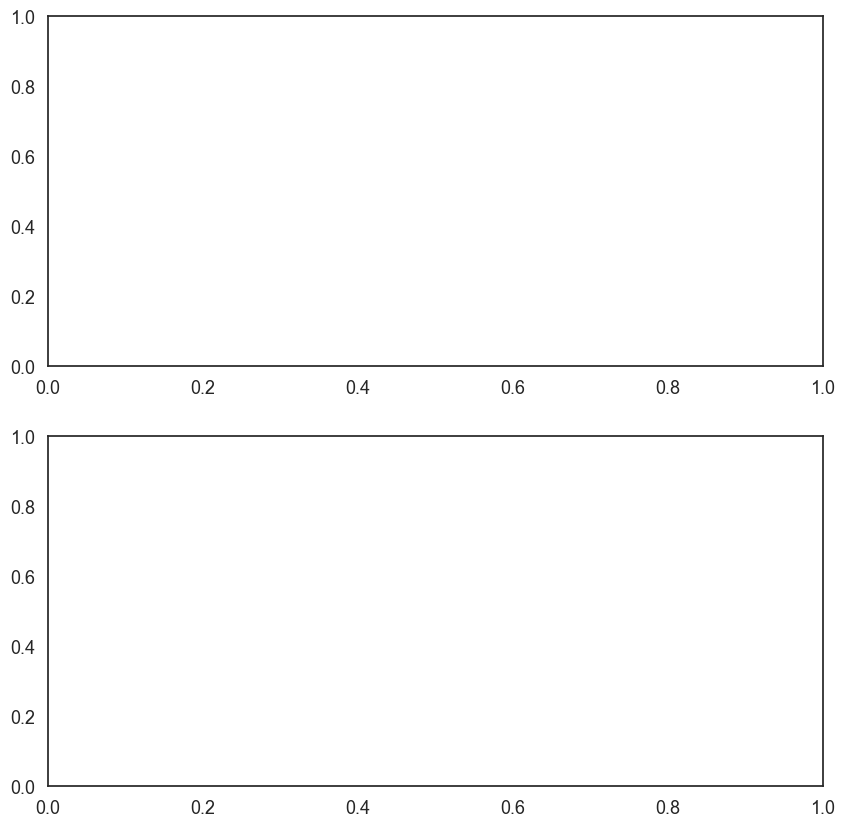

In [42]:
# Plot lithology comparison
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Plot 1: Both lithology curves
ax1 = axes[0]
ax1.plot(z_coords_lith_compare, regular_lith_compare, 'b-', linewidth=2, marker='o', markersize=4, 
         label='Regular Grid Lithology', alpha=0.7)
ax1.plot(z_coords_lith_compare, custom_lith_compare, 'r--', linewidth=2, marker='x', markersize=4, 
         label='Custom Grid Lithology', alpha=0.7)

ax1.set_xlabel('Z coordinate', fontsize=12)
ax1.set_ylabel('Lithology Value', fontsize=12)
ax1.set_title(f'Lithology Comparison at x={x_loc}, y={y_loc}\nRegular Grid vs Custom Grid', fontsize=13)
ax1.legend(loc='best', fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_ylim([-0.5, max(regular_lith_compare.max(), custom_lith_compare.max()) + 0.5])

# Add labels for lithology values
for element in model.structural_frame.structural_elements[:-1]:
    element_id = element.id
    if element_id in regular_lith_compare:
        ax1.axhline(y=element_id, color='g', linestyle=':', linewidth=1, alpha=0.5, 
                   label=f'{element.name} (id={element_id})')

# Plot 2: Difference
ax2 = axes[1]
lith_differences = custom_lith_compare - regular_lith_compare
ax2.plot(z_coords_lith_compare, lith_differences, 'purple', linewidth=2, marker='o', markersize=3)
ax2.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax2.set_xlabel('Z coordinate', fontsize=12)
ax2.set_ylabel('Difference (Custom - Regular)', fontsize=12)
ax2.set_title('Lithology Difference: Custom Grid - Regular Grid', fontsize=13)
ax2.grid(True, alpha=0.3)

# Add statistics
n_different = np.sum(lith_differences != 0)
match_percentage = 100 * (1 - n_different / min_len_lith)
ax2.text(0.02, 0.98, f'Match: {match_percentage:.1f}%\nMismatches: {n_different}/{min_len_lith}', 
         transform=ax2.transAxes, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5), fontsize=10)

plt.tight_layout()
plt.show()

print("\n✓ Lithology comparison plot created")
if lith_match:
    print("✓ Lithology values match perfectly!")
else:
    print(f"⚠️ Lithology values differ at {n_different} points")
    print("   This suggests the custom grid computation itself may have issues")